In [1]:
# Food Delivery Operations Analysis
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the cleaned food delivery dataset

df = pd.read_csv("../01_Dataset/food_delivery_cleaned.csv")

# Display the first five records
df.head()

,order_id,delivery_person_id,delivery_person_age,delivery_person_ratings,restaurant_latitude,restaurant_longitude,delivery_latitude,delivery_longitude,order_date,time_ordered,...,city_was_missing,festival_was_missing,multiple_deliveries_was_missing,coordinates_valid,distance_km_straight_line,on_time_30min,delayed_over_45min,delivery_performance,order_month,order_weekday
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55,...,False,False,False,True,10.280582,0,1,Severely delayed (>45 min),2022-02,Saturday
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,...,False,False,False,True,6.242319,1,0,On time (<=30 min),2022-02,Sunday
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30,...,False,False,False,True,13.787860,1,0,On time (<=30 min),2022-03,Friday
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,...,False,False,False,True,2.930258,1,0,On time (<=30 min),2022-02,Sunday
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,...,False,False,False,True,19.396618,0,0,31-45 min,2022-02,Monday


In [3]:
# Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 45584
Number of columns: 34

Column names:
['order_id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_latitude', 'delivery_longitude', 'order_date', 'time_ordered', 'time_order_picked', 'weather_conditions', 'road_traffic_density', 'vehicle_condition', 'order_type', 'vehicle_type', 'multiple_deliveries', 'festival', 'city', 'time_taken_min', 'age_was_missing', 'rating_was_missing_or_invalid', 'weather_was_missing', 'traffic_was_missing', 'city_was_missing', 'festival_was_missing', 'multiple_deliveries_was_missing', 'coordinates_valid', 'distance_km_straight_line', 'on_time_30min', 'delayed_over_45min', 'delivery_performance', 'order_month', 'order_weekday']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 34 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           -------------- 

In [4]:
# DATA QUALITY CHECK

# 1. Check missing values
print("MISSING VALUES")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())

# 3. Check duplicate order IDs
print("\nDUPLICATE ORDER IDs")
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

# 4. Check zero-distance values
print("\nZERO DISTANCE VALUES")
print(
    "Zero distances:",
    (df["distance_km_straight_line"] == 0).sum()
)

MISSING VALUES
order_id                              0
delivery_person_id                    0
delivery_person_age                   0
delivery_person_ratings               0
restaurant_latitude                   0
restaurant_longitude                  0
delivery_latitude                     0
delivery_longitude                    0
order_date                            0
time_ordered                          0
time_order_picked                     0
weather_conditions                    0
road_traffic_density                  0
vehicle_condition                     0
order_type                            0
vehicle_type                          0
multiple_deliveries                   0
festival                              0
city                                  0
time_taken_min                        0
age_was_missing                       0
rating_was_missing_or_invalid         0
weather_was_missing                   0
traffic_was_missing                   0
city_was_missing         

In [5]:
# Investigate distance column

print("Distance column data type:")
print(df["distance_km_straight_line"].dtype)

print("\nDistance summary:")
print(df["distance_km_straight_line"].describe())

print("\nZero values:")
print((df["distance_km_straight_line"] == 0).sum())

print("\nNegative values:")
print((df["distance_km_straight_line"] < 0).sum())

print("\nFirst 15 distance values:")
print(df["distance_km_straight_line"].head(15).to_string(index=False))

Distance column data type:
float64

Distance summary:
count    41944.000000
mean       107.080686
std       1146.240729
min          1.465067
25%          4.658001
50%          9.220368
75%         13.760880
max      19692.674606
Name: distance_km_straight_line, dtype: float64

Zero values:
0

Negative values:
0

First 15 distance values:
10.280582
 6.242319
13.787860
 2.930258
19.396618
13.763977
 6.218001
16.849940
10.757109
 4.540574
12.256076
19.618739
 1.558132
20.180635
 6.116972


In [6]:
# Distance data quality summary

total_orders = len(df)

missing_distances = df["distance_km_straight_line"].isna().sum()

valid_distances = df["distance_km_straight_line"].notna().sum()

missing_percentage = (missing_distances / total_orders) * 100

print("Total Orders:", total_orders)
print("Valid Distances:", valid_distances)
print("Missing Distances:", missing_distances)
print("Missing Distance Percentage:", round(missing_percentage, 2), "%")

Total Orders: 45584
Valid Distances: 41944
Missing Distances: 3640
Missing Distance Percentage: 7.99 %


In [7]:
# ==========================================
# FOOD DELIVERY OPERATIONS - BUSINESS KPIs
# ==========================================

total_orders = len(df)

average_delivery_time = df["time_taken_min"].mean()

on_time_orders = df["on_time_30min"].sum()

on_time_rate = np.mean(df["on_time_30min"]) * 100

severe_delay_orders = df["delayed_over_45min"].sum()

severe_delay_rate = np.mean(df["delayed_over_45min"]) * 100

# Create KPI summary

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Average Delivery Time",
        "On-Time Orders",
        "On-Time Delivery Rate",
        "Severe Delay Orders",
        "Severe Delay Rate"
    ],
    "Value": [
        total_orders,
        round(average_delivery_time, 2),
        on_time_orders,
        round(on_time_rate, 2),
        severe_delay_orders,
        round(severe_delay_rate, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Orders,45584.00
1,Average Delivery Time,26.29
2,On-Time Orders,31982.00
3,On-Time Delivery Rate,70.16
4,Severe Delay Orders,1562.00
5,Severe Delay Rate,3.43


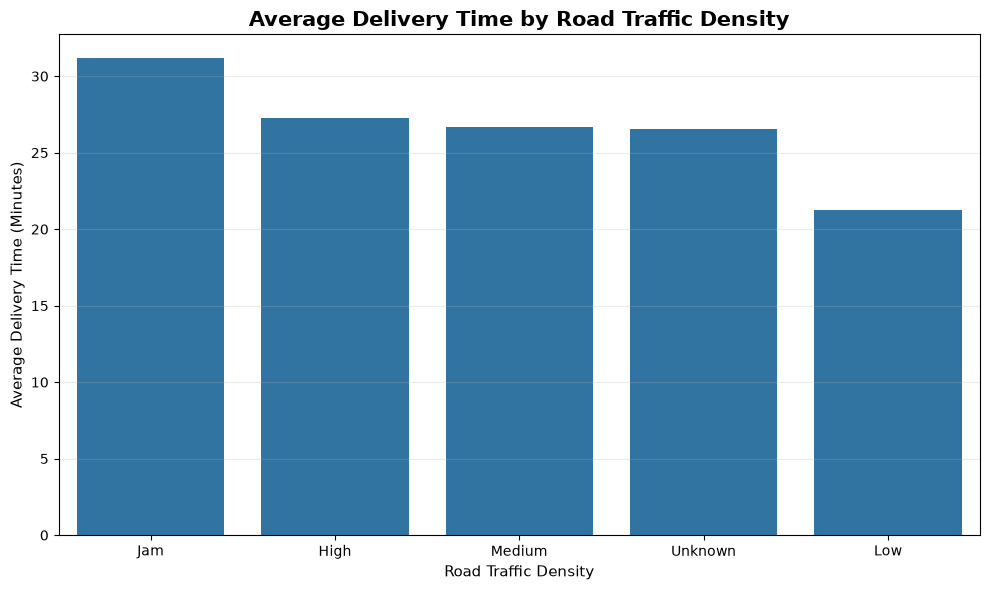

In [8]:
# Average delivery time by traffic density

traffic_analysis = (
    df.groupby("road_traffic_density")["time_taken_min"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=traffic_analysis.index,
    y=traffic_analysis.values
)

plt.title(
    "Average Delivery Time by Road Traffic Density",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Road Traffic Density", fontsize=11)
plt.ylabel("Average Delivery Time (Minutes)", fontsize=11)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

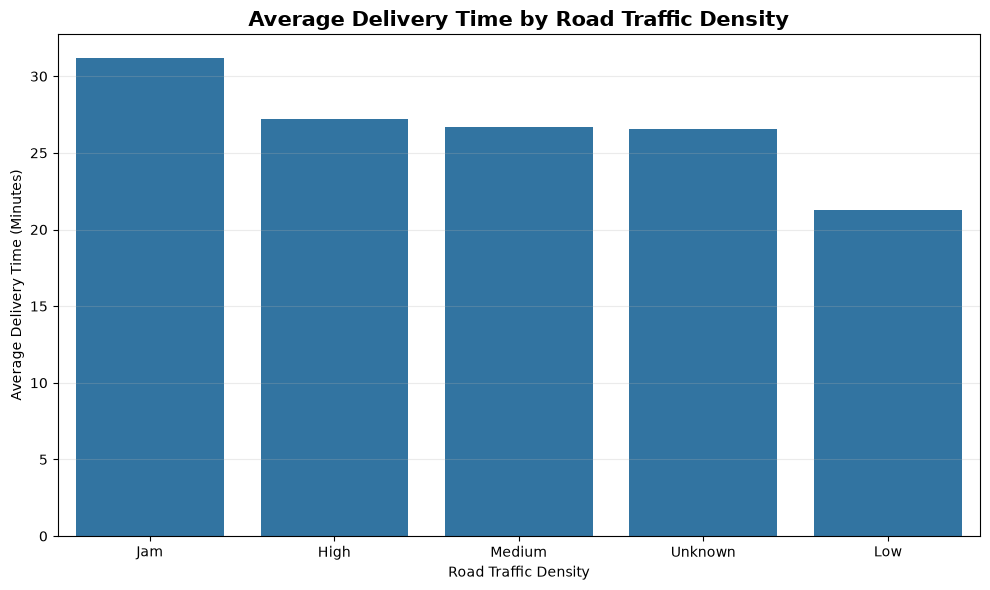

Chart saved successfully!


In [9]:
# Save traffic analysis chart

plt.figure(figsize=(10, 6))

sns.barplot(
    x=traffic_analysis.index,
    y=traffic_analysis.values
)

plt.title(
    "Average Delivery Time by Road Traffic Density",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Road Traffic Density")
plt.ylabel("Average Delivery Time (Minutes)")

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "../05_Charts/01_Traffic_Density_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [10]:
vehicle_analysis = (
    df.groupby("vehicle_type")["time_taken_min"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average Delivery Time by Vehicle Type:")
display(vehicle_analysis)

Average Delivery Time by Vehicle Type:


vehicle_type
motorcycle          27.61
bicycle             26.43
scooter             24.48
electric_scooter    24.47
Name: time_taken_min, dtype: float64

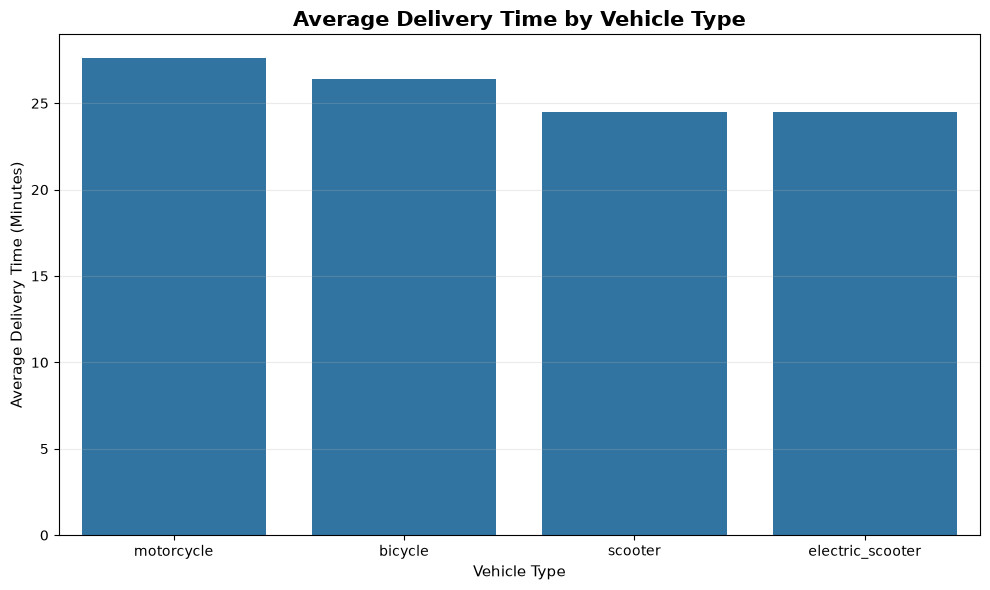

Vehicle chart saved successfully!


In [11]:
# Create vehicle performance chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=vehicle_analysis.index,
    y=vehicle_analysis.values
)

plt.title(
    "Average Delivery Time by Vehicle Type",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Vehicle Type", fontsize=11)
plt.ylabel("Average Delivery Time (Minutes)", fontsize=11)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

# Save chart
from pathlib import Path

charts_folder = Path("../05_Charts")
charts_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_folder / "02_Vehicle_Type_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Vehicle chart saved successfully!")

In [12]:
weather_analysis = (
    df.groupby("weather_conditions")["time_taken_min"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average Delivery Time by Weather:")
display(weather_analysis)

Average Delivery Time by Weather:


weather_conditions
Cloudy        28.92
Fog           28.91
Unknown       26.55
Windy         26.12
Sandstorms    25.88
Stormy        25.87
Sunny         21.86
Name: time_taken_min, dtype: float64

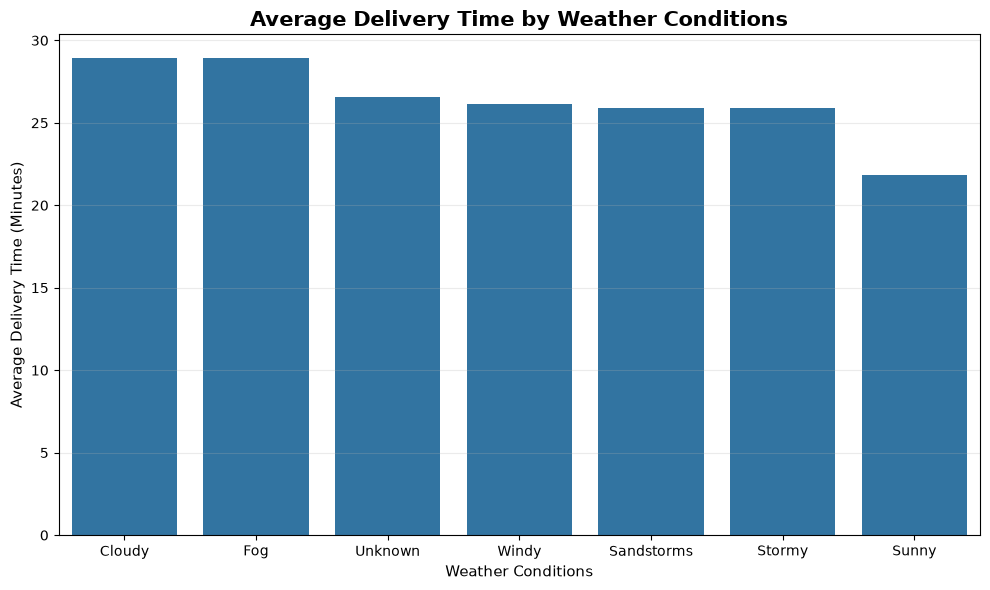

Weather chart saved successfully!


In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weather_analysis.index,
    y=weather_analysis.values
)

plt.title(
    "Average Delivery Time by Weather Conditions",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Weather Conditions", fontsize=11)
plt.ylabel("Average Delivery Time (Minutes)", fontsize=11)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "03_Weather_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weather chart saved successfully!")

In [14]:
festival_analysis = (
    df.groupby("festival")
    .agg(
        Total_Orders=("order_id", "count"),
        Average_Delivery_Time=("time_taken_min", "mean"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

festival_analysis["Average_Delivery_Time"] = (
    festival_analysis["Average_Delivery_Time"].round(2)
)

festival_analysis["Severe_Delay_Rate_%"] = (
    festival_analysis["Severe_Delays"]
    / festival_analysis["Total_Orders"] * 100
).round(2)

display(festival_analysis)

,Total_Orders,Average_Delivery_Time,Severe_Delays,Severe_Delay_Rate_%
festival,,,,
No,44460,25.98,1142,2.57
Unknown,228,11.17,0,0.00
Yes,896,45.52,420,46.88


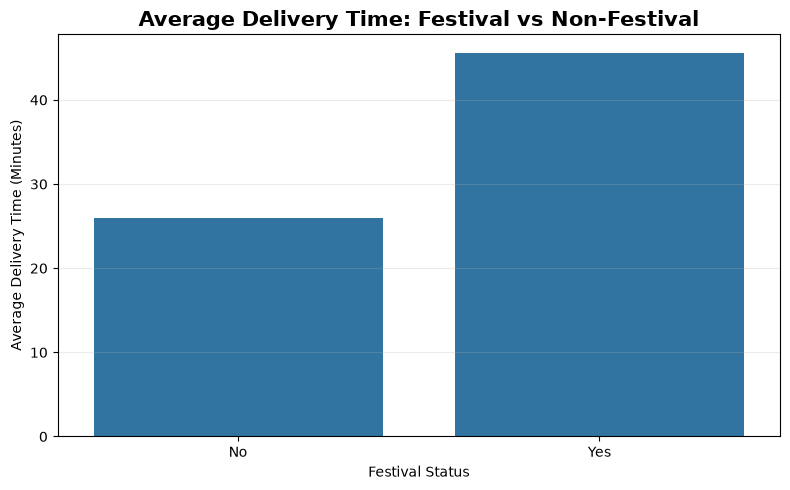

Festival chart saved successfully!


In [15]:
festival_chart = festival_analysis.loc[
    ["No", "Yes"], "Average_Delivery_Time"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=festival_chart.index,
    y=festival_chart.values
)

plt.title(
    "Average Delivery Time: Festival vs Non-Festival",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Festival Status")
plt.ylabel("Average Delivery Time (Minutes)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "04_Festival_Impact_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Festival chart saved successfully!")

In [16]:
city_analysis = (
    df.groupby("city")
    .agg(
        Total_Orders=("order_id", "count"),
        Average_Delivery_Time=("time_taken_min", "mean"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

city_analysis["Average_Delivery_Time"] = (
    city_analysis["Average_Delivery_Time"].round(2)
)

city_analysis["Severe_Delay_Rate_%"] = (
    city_analysis["Severe_Delays"]
    / city_analysis["Total_Orders"] * 100
).round(2)

display(city_analysis)

,Total_Orders,Average_Delivery_Time,Severe_Delays,Severe_Delay_Rate_%
city,,,,
Metropolitian,34087,27.31,1233,3.62
Semi-Urban,164,49.73,159,96.95
Unknown,1200,22.06,10,0.83
Urban,10133,22.98,160,1.58


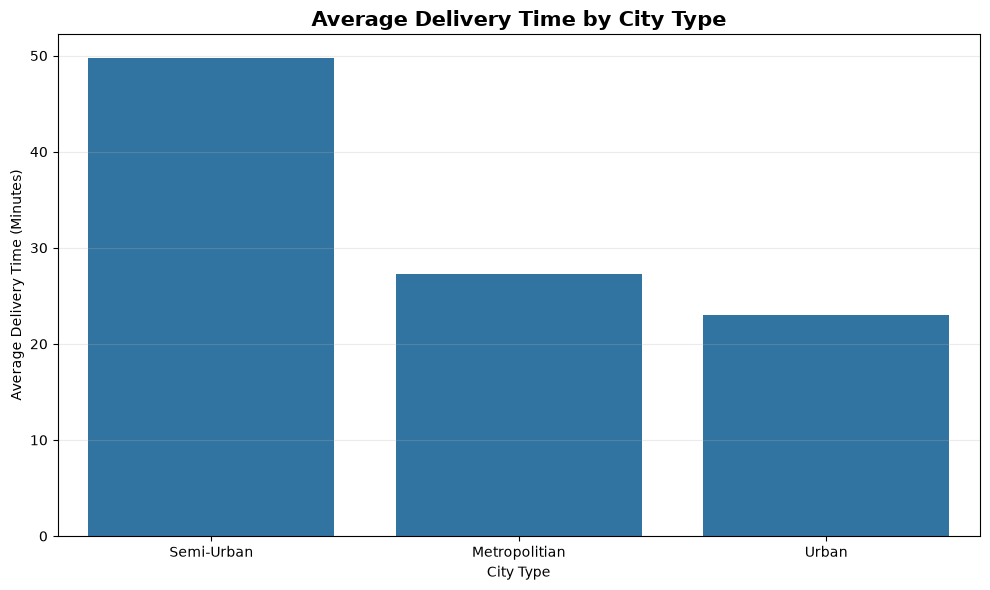

City chart saved successfully!


In [17]:
city_chart = city_analysis.loc[
    ["Metropolitian", "Semi-Urban", "Urban"],
    "Average_Delivery_Time"
].sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_chart.index,
    y=city_chart.values
)

plt.title(
    "Average Delivery Time by City Type",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("City Type")
plt.ylabel("Average Delivery Time (Minutes)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "05_City_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("City chart saved successfully!")

In [19]:
# Create delivery distance groups
df["distance_group"] = pd.cut(
    df["distance_km_straight_line"],
    bins=[0, 2, 4, 6, 8, float("inf")],
    labels=["0-2 km", "2-4 km", "4-6 km", "6-8 km", "Above 8 km"]
)

# Calculate average delivery time
distance_analysis = (
    df.groupby("distance_group", observed=False)
    .agg(
        Total_Orders=("order_id", "count"),
        Average_Delivery_Time=("time_taken_min", "mean")
    )
)

distance_analysis["Average_Delivery_Time"] = (
    distance_analysis["Average_Delivery_Time"].round(2)
)

display(distance_analysis)

,Total_Orders,Average_Delivery_Time
distance_group,,
0-2 km,3746,21.46
2-4 km,3732,21.37
4-6 km,4221,23.90
6-8 km,6966,24.63
Above 8 km,23279,28.82


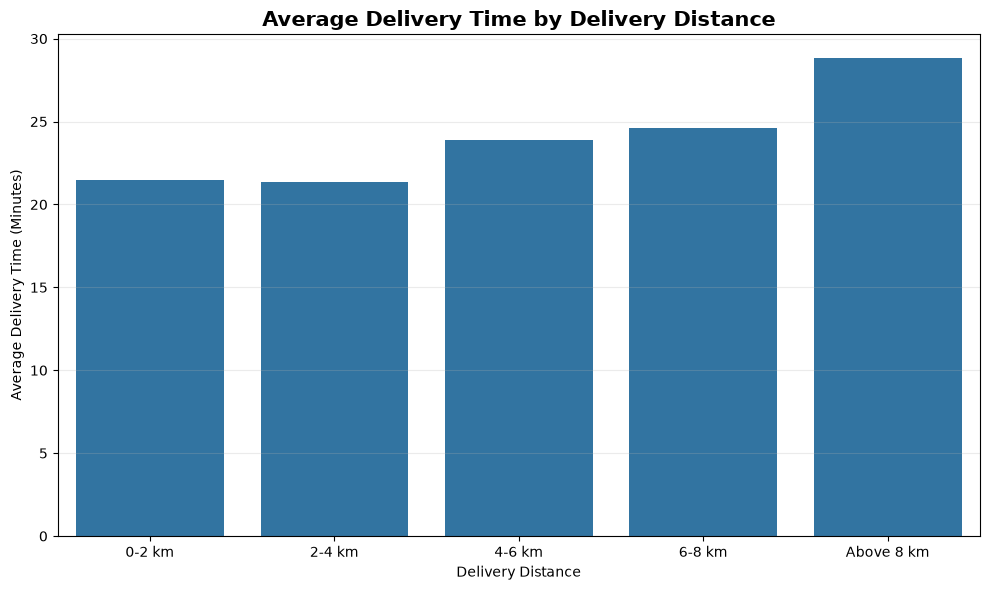

Distance chart saved successfully!


In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=distance_analysis.index,
    y=distance_analysis["Average_Delivery_Time"]
)

plt.title(
    "Average Delivery Time by Delivery Distance",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Delivery Distance")
plt.ylabel("Average Delivery Time (Minutes)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "06_Distance_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Distance chart saved successfully!")

In [21]:
vehicle_delay_analysis = (
    df.groupby("vehicle_type")
    .agg(
        Total_Orders=("order_id", "count"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

vehicle_delay_analysis["Severe_Delay_Rate_%"] = (
    vehicle_delay_analysis["Severe_Delays"]
    / vehicle_delay_analysis["Total_Orders"] * 100
).round(2)

vehicle_delay_analysis = vehicle_delay_analysis.sort_values(
    "Severe_Delay_Rate_%", ascending=False
)

display(vehicle_delay_analysis)

,Total_Orders,Severe_Delays,Severe_Delay_Rate_%
vehicle_type,,,
motorcycle,26429,1371,5.19
bicycle,68,2,2.94
scooter,15273,155,1.01
electric_scooter,3814,34,0.89


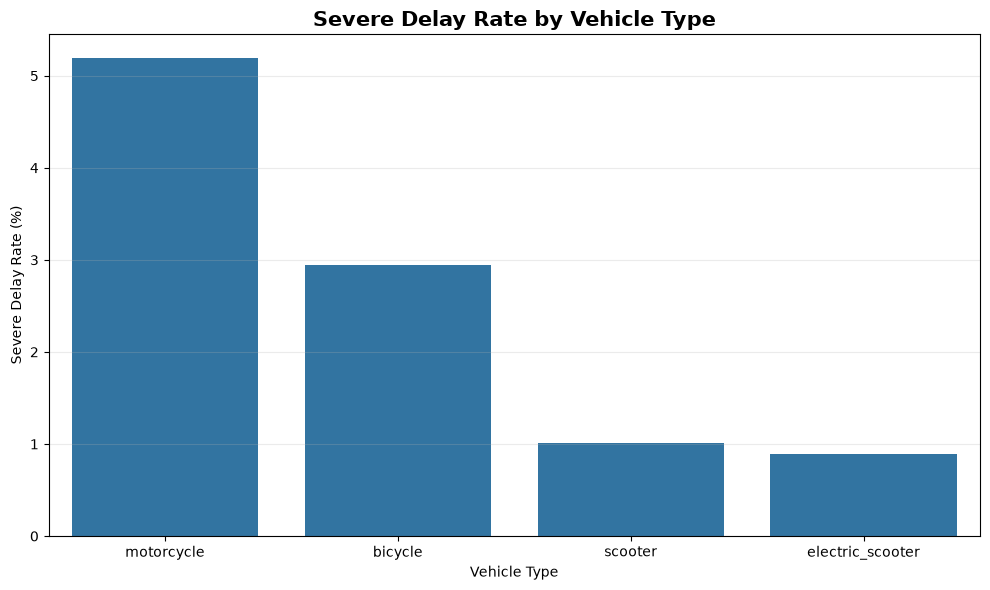

Severe-delay vehicle chart saved successfully!


In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=vehicle_delay_analysis.index,
    y=vehicle_delay_analysis["Severe_Delay_Rate_%"]
)

plt.title(
    "Severe Delay Rate by Vehicle Type",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Vehicle Type")
plt.ylabel("Severe Delay Rate (%)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "07_Severe_Delay_by_Vehicle.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Severe-delay vehicle chart saved successfully!")


In [23]:
weather_delay_analysis = (
    df.groupby("weather_conditions")
    .agg(
        Total_Orders=("order_id", "count"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

weather_delay_analysis["Severe_Delay_Rate_%"] = (
    weather_delay_analysis["Severe_Delays"]
    / weather_delay_analysis["Total_Orders"] * 100
).round(2)

weather_delay_analysis = weather_delay_analysis.sort_values(
    "Severe_Delay_Rate_%", ascending=False
)

display(weather_delay_analysis)

,Total_Orders,Severe_Delays,Severe_Delay_Rate_%
weather_conditions,,,
Cloudy,7533,413,5.48
Fog,7653,393,5.14
Unknown,616,23,3.73
Sandstorms,7494,207,2.76
Windy,7422,197,2.65
Stormy,7584,184,2.43
Sunny,7282,145,1.99


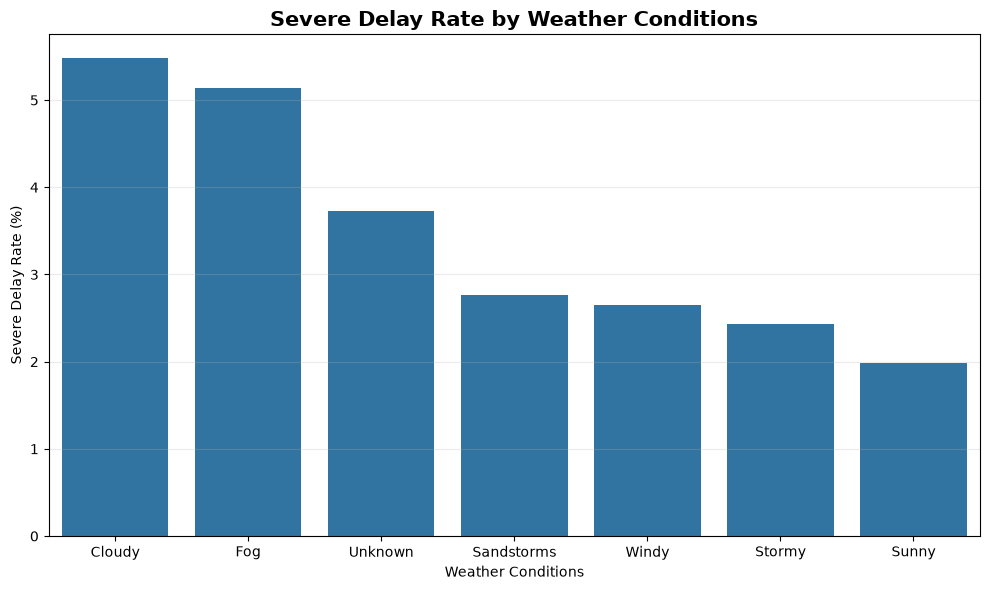

Weather severe-delay chart saved successfully!


In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weather_delay_analysis.index,
    y=weather_delay_analysis["Severe_Delay_Rate_%"]
)

plt.title(
    "Severe Delay Rate by Weather Conditions",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Weather Conditions")
plt.ylabel("Severe Delay Rate (%)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "08_Severe_Delay_by_Weather.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weather severe-delay chart saved successfully!")

In [25]:
traffic_delay_analysis = (
    df.groupby("road_traffic_density")
    .agg(
        Total_Orders=("order_id", "count"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

traffic_delay_analysis["Severe_Delay_Rate_%"] = (
    traffic_delay_analysis["Severe_Delays"]
    / traffic_delay_analysis["Total_Orders"] * 100
).round(2)

traffic_delay_analysis = traffic_delay_analysis.sort_values(
    "Severe_Delay_Rate_%", ascending=False
)

display(traffic_delay_analysis)

,Total_Orders,Severe_Delays,Severe_Delay_Rate_%
road_traffic_density,,,
Jam,14139,1200,8.49
Unknown,601,21,3.49
High,4423,151,3.41
Medium,10945,190,1.74
Low,15476,0,0.00


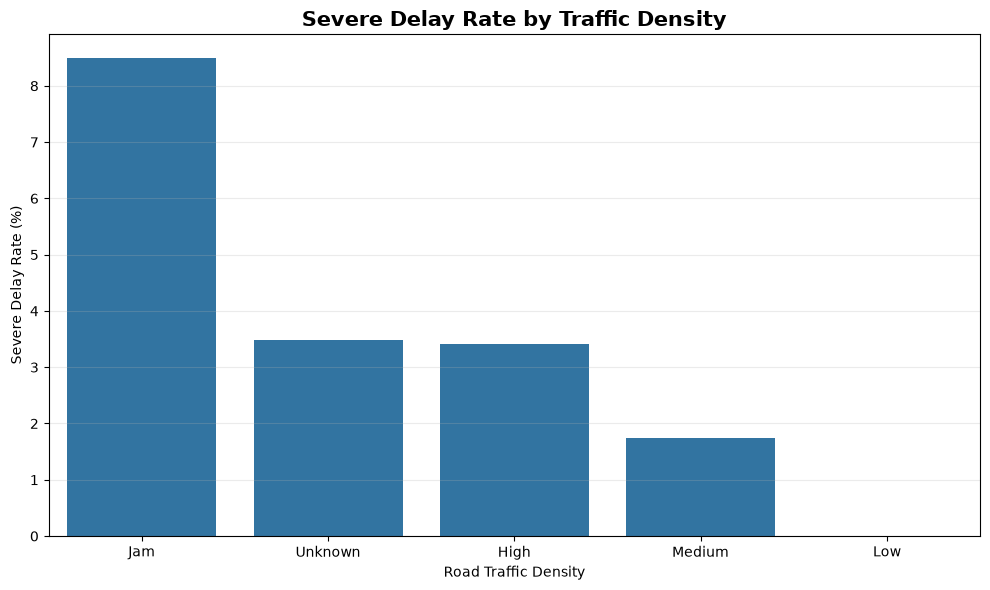

Traffic severe-delay chart saved successfully!


In [26]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=traffic_delay_analysis.index,
    y=traffic_delay_analysis["Severe_Delay_Rate_%"]
)

plt.title(
    "Severe Delay Rate by Traffic Density",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Road Traffic Density")
plt.ylabel("Severe Delay Rate (%)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    charts_folder / "09_Severe_Delay_by_Traffic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Traffic severe-delay chart saved successfully!")

In [27]:
traffic_weather_analysis = (
    df.groupby(
        ["road_traffic_density", "weather_conditions"]
    )
    .agg(
        Total_Orders=("order_id", "count"),
        Average_Delivery_Time=("time_taken_min", "mean"),
        Severe_Delays=("delayed_over_45min", "sum")
    )
)

traffic_weather_analysis["Average_Delivery_Time"] = (
    traffic_weather_analysis["Average_Delivery_Time"].round(2)
)

traffic_weather_analysis["Severe_Delay_Rate_%"] = (
    traffic_weather_analysis["Severe_Delays"]
    / traffic_weather_analysis["Total_Orders"] * 100
).round(2)

# Show combinations with at least 100 orders
traffic_weather_analysis = (
    traffic_weather_analysis[
        traffic_weather_analysis["Total_Orders"] >= 100
    ]
    .sort_values("Average_Delivery_Time", ascending=False)
)

display(traffic_weather_analysis.head(15))

Total_Orders  Average_Delivery_Time  \
road_traffic_density weather_conditions                                        
Jam                  Fog                         2428                  36.81   
                     Cloudy                      2348                  36.69   
                     Windy                       2351                  30.22   
                     Sandstorms                  2399                  30.02   
                     Stormy                      2321                  29.85   
High                 Cloudy                       743                  28.94   
Medium               Cloudy                      1837                  28.48   
High                 Fog                          776                  28.43   
Medium               Fog                         1852                  28.04   
                     Windy                       1852                  27.89   
High                 Stormy                       733                  27.85   
Medium               Sandstorms                  1786                  27.74   
High                 Sandstorms                   701                  27.71   
Medium               Stormy                      1831                  27.68   
High                 Windy                        735                  26.97   

                                         Severe_Delays  Severe_Delay_Rate_%  
road_traffic_density weather_conditions                                      
Jam                  Fog                           358                14.74  
                     Cloudy                        369                15.72  
                     Windy                         135                 5.74  
                     Sandstorms                    140                 5.84  
                     Stormy                        125                 5.39  
High                 Cloudy                          0                 0.00  
Medium               Cloudy                         44                 2.40  
High                 Fog                             0                 0.00  
Medium               Fog                            35                 1.89  
                     Windy                          38                 2.05  
High                 Stormy                         24                 3.27  
Medium               Sandstorms                     38                 2.13  
High                 Sandstorms                     29                 4.14  
Medium               Stormy                         35                 1.91  
High                 Windy                          24                 3.27

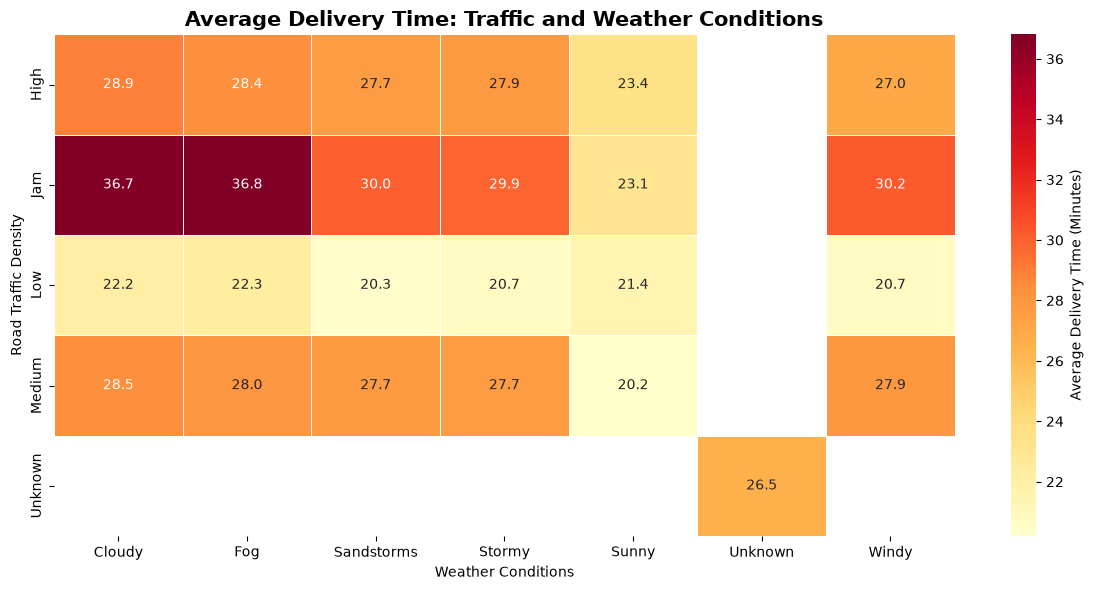

Traffic and weather heatmap saved successfully!


In [28]:
# Prepare data for the heatmap
traffic_weather_pivot = (
    traffic_weather_analysis
    .reset_index()
    .pivot(
        index="road_traffic_density",
        columns="weather_conditions",
        values="Average_Delivery_Time"
    )
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    traffic_weather_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Average Delivery Time (Minutes)"}
)

plt.title(
    "Average Delivery Time: Traffic and Weather Conditions",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Weather Conditions")
plt.ylabel("Road Traffic Density")
plt.tight_layout()

plt.savefig(
    charts_folder / "10_Traffic_Weather_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Traffic and weather heatmap saved successfully!")

In [29]:
# Identify the 10 largest delivery distances
distance_outliers = (
    df[[
        "order_id",
        "distance_km_straight_line",
        "time_taken_min",
        "city",
        "coordinates_valid"
    ]]
    .nlargest(10, "distance_km_straight_line")
)

display(distance_outliers)

,order_id,distance_km_straight_line,time_taken_min,city,coordinates_valid
33524,0xbf01,19692.674606,28,Metropolitian,True
6779,0xc014,19688.001288,46,Metropolitian,True
2475,0xbf10,19683.687561,22,Metropolitian,True
18817,0xc012,19677.180552,15,Urban,True
9526,0x3ef,19070.408110,32,Metropolitian,True
753,0x462,19070.337839,15,Metropolitian,True
35526,0x509,19069.158946,29,Metropolitian,True
22282,0x3ed,19068.246962,44,Metropolitian,True
30624,0x481,19067.128547,29,Metropolitian,True
43445,0x4d7,19066.150742,21,Urban,True


In [30]:
distance_outliers = df.nlargest(
    10, "distance_km_straight_line"
)[[
    "order_id",
    "restaurant_latitude",
    "restaurant_longitude",
    "delivery_latitude",
    "delivery_longitude",
    "distance_km_straight_line",
    "time_taken_min",
    "city"
]]

print(distance_outliers.to_string(index=False))

order_id  restaurant_latitude  restaurant_longitude  delivery_latitude  delivery_longitude  distance_km_straight_line  time_taken_min          city
  0xbf01           -22.533662            -88.366217          22.663662           88.496217               19692.674606              28 Metropolitian
  0xc014           -22.552672            -88.352885          22.662672           88.462885               19688.001288              46 Metropolitian
  0xbf10           -22.538999            -88.322337          22.668999           88.452337               19683.687561              22 Metropolitian
  0xc012           -22.537960            -88.349843          22.547960           88.359843               19677.180552              15         Urban
   0x3ef           -23.374989            -85.335486          23.444989           85.405486               19070.408110              32 Metropolitian
   0x462           -23.359194            -85.325447          23.449194           85.415447               19070.3

In [31]:
# Count coordinate sign mismatches
latitude_sign_mismatch = (
    np.sign(df["restaurant_latitude"])
    != np.sign(df["delivery_latitude"])
).sum()

longitude_sign_mismatch = (
    np.sign(df["restaurant_longitude"])
    != np.sign(df["delivery_longitude"])
).sum()

both_sign_mismatch = (
    (np.sign(df["restaurant_latitude"]) != np.sign(df["delivery_latitude"]))
    &
    (np.sign(df["restaurant_longitude"]) != np.sign(df["delivery_longitude"]))
).sum()

print("LATITUDE SIGN MISMATCHES:", latitude_sign_mismatch)
print("LONGITUDE SIGN MISMATCHES:", longitude_sign_mismatch)
print("BOTH LATITUDE AND LONGITUDE MISMATCH:", both_sign_mismatch)

LATITUDE SIGN MISMATCHES: 4071
LONGITUDE SIGN MISMATCHES: 3802
BOTH LATITUDE AND LONGITUDE MISMATCH: 3802


In [32]:
# Count distances above 50 km
suspicious_distances = df[
    df["distance_km_straight_line"] > 50
]

print("Orders with distance above 50 km:",
      len(suspicious_distances))

print("Percentage of all orders:",
      round(len(suspicious_distances) / len(df) * 100, 2), "%")

print("Maximum recorded distance:",
      round(df["distance_km_straight_line"].max(), 2), "km")

Orders with distance above 50 km: 431
Percentage of all orders: 0.95 %
Maximum recorded distance: 19692.67 km


In [33]:
# Separate plausible and suspicious distance records
valid_distance = df[
    df["distance_km_straight_line"].between(0, 50)
]

print("Total orders:", len(df))
print("Orders with plausible distance:", len(valid_distance))
print("Orders with suspicious distance:", len(suspicious_distances))
print("Orders with missing distance:",
      df["distance_km_straight_line"].isna().sum())

print("\nPlausible distance statistics:")
print(valid_distance["distance_km_straight_line"].describe().round(2))

Total orders: 45584
Orders with plausible distance: 41513
Orders with suspicious distance: 431
Orders with missing distance: 3640

Plausible distance statistics:
count    41513.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97
Name: distance_km_straight_line, dtype: float64


In [34]:
# Create a separate dataset for distance analysis
distance_df = df[
    df["distance_km_straight_line"].between(0, 50)
].copy()

print("Original dataset:", df.shape)
print("Distance analysis dataset:", distance_df.shape)

print("\nMissing distances remaining:",
      distance_df["distance_km_straight_line"].isna().sum())

print("Distances above 50 km remaining:",
      (distance_df["distance_km_straight_line"] > 50).sum())

Original dataset: (45584, 35)
Distance analysis dataset: (41513, 35)

Missing distances remaining: 0
Distances above 50 km remaining: 0


In [35]:
distance_relationship = (
    distance_df.groupby("distance_group", observed=False)
    .agg(
        Total_Orders=("order_id", "count"),
        Average_Distance=("distance_km_straight_line", "mean"),
        Average_Delivery_Time=("time_taken_min", "mean")
    )
)

distance_relationship = distance_relationship.round(2)

display(distance_relationship)

,Total_Orders,Average_Distance,Average_Delivery_Time
distance_group,,,
0-2 km,3746,1.53,21.46
2-4 km,3732,3.06,21.37
4-6 km,4221,4.75,23.90
6-8 km,6966,6.95,24.63
Above 8 km,22848,13.91,28.88


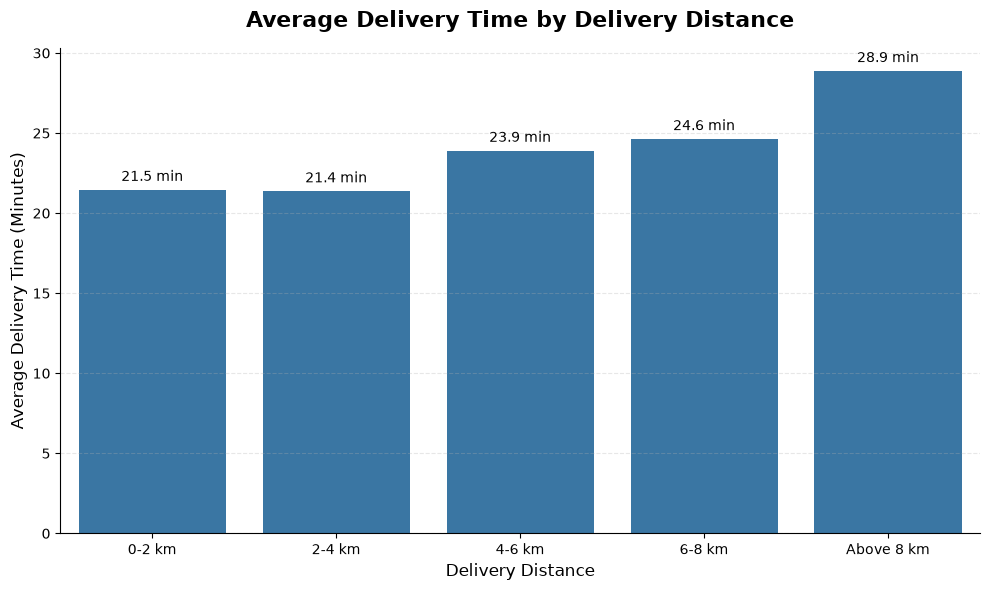

In [36]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=distance_relationship.reset_index(),
    x="distance_group",
    y="Average_Delivery_Time",
    color="#2878B5"
)

plt.title(
    "Average Delivery Time by Delivery Distance",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Delivery Distance", fontsize=12)
plt.ylabel("Average Delivery Time (Minutes)", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f min", padding=4)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

plt.savefig(
    "../05_Charts/11_Distance_vs_Delivery_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
print("DELIVERY TIME STATISTICS")
print(df["time_taken_min"].describe().round(2))

print("\nDELIVERY TIMES BELOW 10 MINUTES:")
print((df["time_taken_min"] < 10).sum())

print("\nDELIVERY TIMES ABOVE 45 MINUTES:")
print((df["time_taken_min"] > 45).sum())

DELIVERY TIME STATISTICS
count    45584.00
mean        26.29
std          9.38
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Name: time_taken_min, dtype: float64

DELIVERY TIMES BELOW 10 MINUTES:
0

DELIVERY TIMES ABOVE 45 MINUTES:
1562


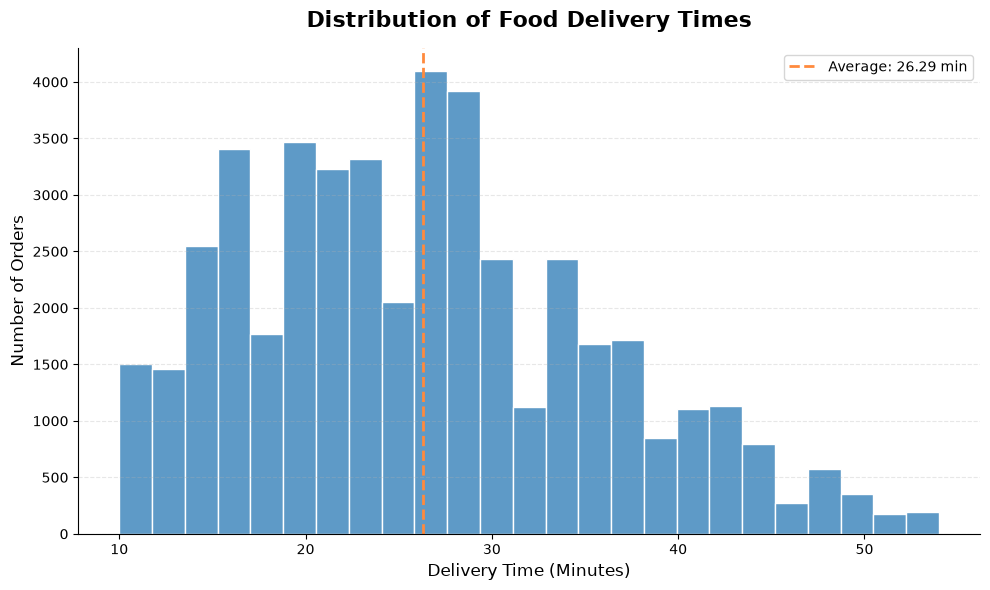

In [38]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="time_taken_min",
    bins=25,
    color="#2878B5",
    edgecolor="white"
)

plt.axvline(
    df["time_taken_min"].mean(),
    color="#FF8A3D",
    linestyle="--",
    linewidth=2,
    label="Average: 26.29 min"
)

plt.title(
    "Distribution of Food Delivery Times",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Delivery Time (Minutes)", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

plt.savefig(
    "../05_Charts/12_Delivery_Time_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Validate delivery performance flags against actual delivery time

on_time_check = (
    df["on_time_30min"]
    == (df["time_taken_min"] <= 30).astype(int)
)

severe_delay_check = (
    df["delayed_over_45min"]
    == (df["time_taken_min"] > 45).astype(int)
)

print("Incorrect on-time flags:", (~on_time_check).sum())
print("Incorrect severe-delay flags:", (~severe_delay_check).sum())

print("\nBoth flags are accurate:",
      on_time_check.all() and severe_delay_check.all())

Incorrect on-time flags: 0
Incorrect severe-delay flags: 0

Both flags are accurate: True


In [40]:
final_kpis = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Average Delivery Time (min)",
        "Median Delivery Time (min)",
        "On-Time Orders",
        "On-Time Delivery Rate (%)",
        "Severe Delay Orders",
        "Severe Delay Rate (%)",
        "Orders with Missing Distance",
        "Orders with Suspicious Distance"
    ],
    "Value": [
        len(df),
        round(df["time_taken_min"].mean(), 2),
        round(df["time_taken_min"].median(), 2),
        int(df["on_time_30min"].sum()),
        round(df["on_time_30min"].mean() * 100, 2),
        int(df["delayed_over_45min"].sum()),
        round(df["delayed_over_45min"].mean() * 100, 2),
        int(df["distance_km_straight_line"].isna().sum()),
        int((df["distance_km_straight_line"] > 50).sum())
    ]
})

display(final_kpis)

,Metric,Value
0,Total Orders,45584.00
1,Average Delivery Time (min),26.29
2,Median Delivery Time (min),26.00
3,On-Time Orders,31982.00
4,On-Time Delivery Rate (%),70.16
5,Severe Delay Orders,1562.00
6,Severe Delay Rate (%),3.43
7,Orders with Missing Distance,3640.00
8,Orders with Suspicious Distance,431.00


In [41]:
final_kpis.to_csv(
    "../05_Charts/13_Final_Python_KPI_Summary.csv",
    index=False
)

print("Final KPI summary exported successfully!")

Final KPI summary exported successfully!
